# Get the Data

In [1]:
import pandas as pd

flights = pd.read_csv("data/flights.csv.zip")
airlines = pd.read_csv("data/airlines.csv")

print(flights.head(3).to_string())
print(airlines.head(3).to_string())

   year  month  day  dep_time  sched_dep_time  dep_delay  arr_time  sched_arr_time  arr_delay carrier  flight tailnum origin dest  air_time  distance  hour  minute             time_hour
0  2013      1    1     517.0             515        2.0     830.0             819       11.0      UA    1545  N14228    EWR  IAH     227.0      1400     5      15  2013-01-01T10:00:00Z
1  2013      1    1     533.0             529        4.0     850.0             830       20.0      UA    1714  N24211    LGA  IAH     227.0      1416     5      29  2013-01-01T10:00:00Z
2  2013      1    1     542.0             540        2.0     923.0             850       33.0      AA    1141  N619AA    JFK  MIA     160.0      1089     5      40  2013-01-01T10:00:00Z
  carrier                    name
0      9E       Endeavor Air Inc.
1      AA  American Airlines Inc.
2      AS    Alaska Airlines Inc.


# 1. Build the analysis sample

In [2]:
# (a)

# Show the number of rows and columns in each file
print("Flights shape:", flights.shape)
print("Airlines shape:", airlines.shape)

# State what one row represents in each file
print("One row in flights represents one scheduled flight record.")
print("One row in airlines represents one carrier code and its airline name.")

# Check the type of arrival delay
print("arr_delay type:", flights["arr_delay"].dtype)

# Count exact duplicate flight rows across all original columns
print("Exact duplicate flight rows:", flights.duplicated().sum())

Flights shape: (336776, 19)
Airlines shape: (16, 2)
One row in flights represents one scheduled flight record.
One row in airlines represents one carrier code and its airline name.
arr_delay type: float64
Exact duplicate flight rows: 0


No flight rows need removing because the exact duplicate count is 0.

In [3]:
# (b)

known = flights["arr_delay"].notna().sum()
missing = flights["arr_delay"].isna().sum()

print("Known arrival delays:", known)
print("Missing arrival delays:", missing)
print("Total:", known + missing)
print("Flight rows:", len(flights))
print("Counts add up to flight total:", known + missing == len(flights))

Known arrival delays: 327346
Missing arrival delays: 9430
Total: 336776
Flight rows: 336776
Counts add up to flight total: True


In [4]:
#late-arrival indicator for delays of 15 minutes or more.

flights["late_arrival"] = (
    flights["arr_delay"].ge(15)
    .where(flights["arr_delay"].notna())
    .astype("Int64")
)

examples = pd.Series([-5, 14, 15, float("nan")], name="arr_delay")
examples_late = (
    examples.ge(15)
    .where(examples.notna())
    .astype("Int64")
)

print(pd.DataFrame({
    "arr_delay": examples,
    "late_arrival": examples_late
}))

   arr_delay  late_arrival
0       -5.0             0
1       14.0             0
2       15.0             1
3        NaN          <NA>


1. `flights["arr_delay"].ge(15)` checks each flight’s arrival delay against 15 minutes. It returns `True` for delays of 15 minutes or more, and `False` for smaller delays.

2. `.where(flights["arr_delay"].notna())` keeps that result when the delay exists. If the delay is missing, it replaces the result with a missing value. This prevents a missing delay from being counted as “not late.”

3. `.astype("Int64")` converts `True` and `False` to `1` and `0`. The capital `I` allows this integer type to preserve missing values, shown as `<NA>`.

# 2. Attach the airline names

In [5]:
#checking whether every carrier code in the airline lookup appears only once.

print("Unique carrier codes:", airlines["carrier"].is_unique)
print("Duplicate carrier codes:", airlines["carrier"].duplicated().sum())

Unique carrier codes: True
Duplicate carrier codes: 0


In [6]:
#joining the airline names onto the flights. A left join keeps every flight record
#and validate="many_to_one" asks pandas to check that many flight rows can match each single lookup row.

rows_before = len(flights)

flights_named = flights.merge(
    airlines,
    on="carrier",
    how="left",
    validate="many_to_one",
    indicator=True
) 

#"validate="many_to_one" If a carrier code appears more than once in the airline lookup, pandas raises an error instead of silently duplicating flight records.
#used "indicator=True", pandas added _merge, which marks each row as both (matched) or left_only (unmatched)

print("Rows before join:", rows_before)
print("Rows after join:", len(flights_named))

unmatched_flights = flights_named["_merge"].eq("left_only").sum()
print("Flights with unmatched carrier codes:", unmatched_flights)

Rows before join: 336776
Rows after join: 336776
Flights with unmatched carrier codes: 0


# 3. Give the editor a table they can check

In [7]:
#(a) 

#rank airlines by their number of scheduled flight records

airline_flights = (
    flights_named.groupby("name")
    .size()
    .sort_values(ascending=False)
)

print(airline_flights.head(5).to_string())

name
United Air Lines Inc.       58665
JetBlue Airways             54635
ExpressJet Airlines Inc.    54173
Delta Air Lines Inc.        48110
American Airlines Inc.      32729


In [8]:
summary = (
    flights_named.groupby("name", as_index=False)
    .agg(
        scheduled_flights=("carrier", "size"),
        known_arrival_delays=("arr_delay", "count"),
        late_arrivals=("late_arrival", "sum")
    )
)

summary["percent_late"] = (
    summary["late_arrivals"] / summary["known_arrival_delays"] * 100
)

top_five = summary.nlargest(5, "scheduled_flights")

all_airlines = pd.DataFrame([{
    "name": "All airlines",
    "scheduled_flights": len(flights_named),
    "known_arrival_delays": flights_named["arr_delay"].count(),
    "late_arrivals": flights_named["late_arrival"].sum()
}])
all_airlines["percent_late"] = (
    all_airlines["late_arrivals"]
    / all_airlines["known_arrival_delays"]
    * 100
)

table = pd.concat([top_five, all_airlines], ignore_index=True)

# Round only the displayed percentage to one decimal place
table_display = table.rename(columns={
    "name": "Airline",
    "scheduled_flights": "Scheduled flights",
    "known_arrival_delays": "Flights with known arrival delay",
    "late_arrivals": "Late arrivals (15+ min)",
    "percent_late": "Late among known delays (%)"
}).copy()

table_display["Late among known delays (%)"] = (
    table_display["Late among known delays (%)"].round(1)
)

table_display.style.hide(axis="index")

Airline,Scheduled flights,Flights with known arrival delay,Late arrivals (15+ min),Late among known delays (%)
United Air Lines Inc.,58665,57782,13004,22.500000
JetBlue Airways,54635,54049,14567,27.000000
ExpressJet Airlines Inc.,54173,51108,16399,32.100000
Delta Air Lines Inc.,48110,47658,9038,19.000000
American Airlines Inc.,32729,31947,6203,19.400000
All airlines,336776,327346,80100,24.500000


In [15]:
# (b)

united_flights = flights_named[
    flights_named["name"] == "United Air Lines Inc."
]

united_known = united_flights["arr_delay"].notna().sum()
united_late = united_flights["late_arrival"].eq(1).sum()
united_percent = united_late / united_known * 100

table_percent = table.loc[
    table["name"] == "United Air Lines Inc.",
    "percent_late"
].iloc[0]

print(f"{united_late} / {united_known} * 100 = {united_percent:.1f}%")
print("Table percentage:", round(table_percent, 1))
print("Arithmetic agrees with the table:", united_percent == table_percent)

13004 / 57782 * 100 = 22.5%
Table percentage: 22.5
Arithmetic agrees with the table: True


In [10]:
# (c)

all_row = table.loc[table["name"] == "All airlines"].iloc[0]

alternative_rate = (
    all_row["late_arrivals"] / all_row["scheduled_flights"] * 100
)
headline_rate = all_row["percent_late"]
difference = alternative_rate - headline_rate

print(f"Alternative rate: {alternative_rate:.1f}%")
print(f"Headline rate: {headline_rate:.1f}%")
print(f"Change: {difference:.1f} percentage points")

Alternative rate: 23.8%
Headline rate: 24.5%
Change: -0.7 percentage points


The alternative denominator counts all scheduled flights, including the 9,430 flights with missing arrival delays. Those flights’ arrival outcomes are unknown, but they are included in the denominator.

# 4. Pitch and illustrate your own finding 

### (a) The pitch

**Reader:** A travel editor comparing New York City airports.

**Question:** What share of flights from EWR, JFK, and LGA arrived at least 15 minutes late?

**Measure and sample:** For each airport, I calculate the percentage of flights with a known arrival delay that arrived at least 15 minutes late. The analysis includes flights scheduled from the three airports in 2013 and excludes flights with missing arrival delays. The figure is based on 327346 flights: 117127 from EWR, 109079 from JFK, and 101140 from LGA.

In [11]:
# how many flights meet that rule, overall and at each airport.

figure_data = flights_named[
    flights_named["arr_delay"].notna()
]

print("Flights behind the figure:", len(figure_data))
print(figure_data.groupby("origin").size().to_string())

Flights behind the figure: 327346
origin
EWR    117127
JFK    109079
LGA    101140


### (b) The figure

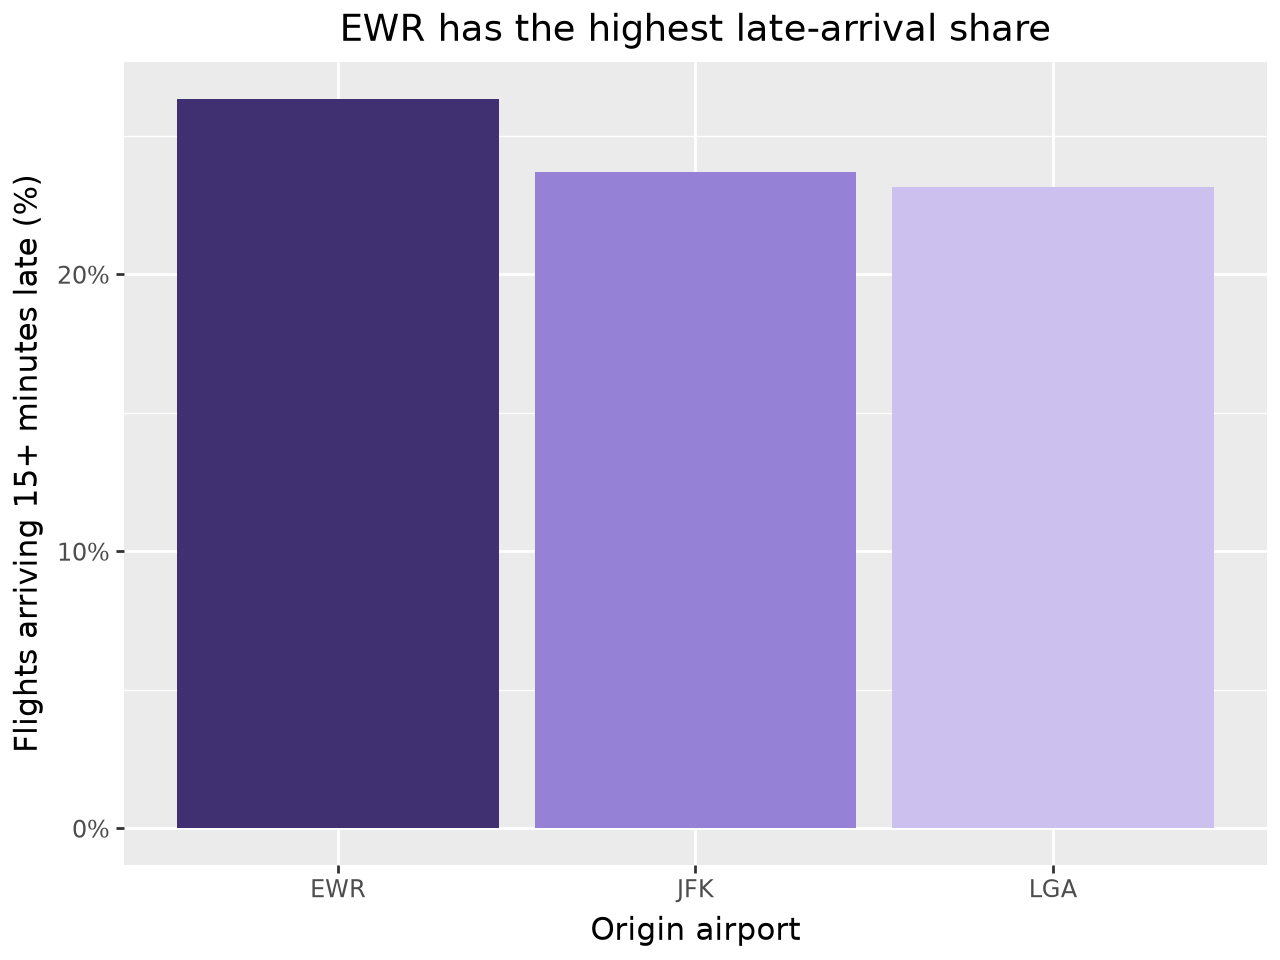

In [12]:
from plotnine import (
    aes, geom_col, ggplot, labs, scale_fill_manual,
    scale_y_continuous, theme
)

airport_summary = (
    figure_data.groupby("origin", as_index=False)
    .agg(
        known_arrival_delays=("arr_delay", "count"),
        late_arrivals=("late_arrival", "sum")
    )
)

airport_summary["late_percent"] = (
    airport_summary["late_arrivals"]
    / airport_summary["known_arrival_delays"]
    * 100
)

airport_summary["late_label"] = airport_summary["late_percent"].map(
    lambda value: f"{value:.1f}%"
)

airport_summary["origin"] = pd.Categorical(
    airport_summary["origin"],
    categories=["EWR", "JFK", "LGA"],
    ordered=True
)
airport_summary = airport_summary.sort_values("origin")

highest = airport_summary.loc[airport_summary["late_percent"].idxmax()]

figure_v1 = (
    ggplot(airport_summary, aes(x="origin", y="late_percent", fill="origin"))
    + geom_col()
    + scale_fill_manual(values={
        "EWR": "#403071",
        "JFK": "#9581D6",
        "LGA": "#CCC1EE"
    })
    + scale_y_continuous(
        labels=lambda values: [f"{value:.0f}%" for value in values]
    )
    + labs(
        title=f"{highest['origin']} has the highest late-arrival share",
        x="Origin airport",
        y="Flights arriving 15+ minutes late (%)",
        fill="Airport"
    )
    + theme(legend_position="none")
)

figure_v1

### (c) The edit

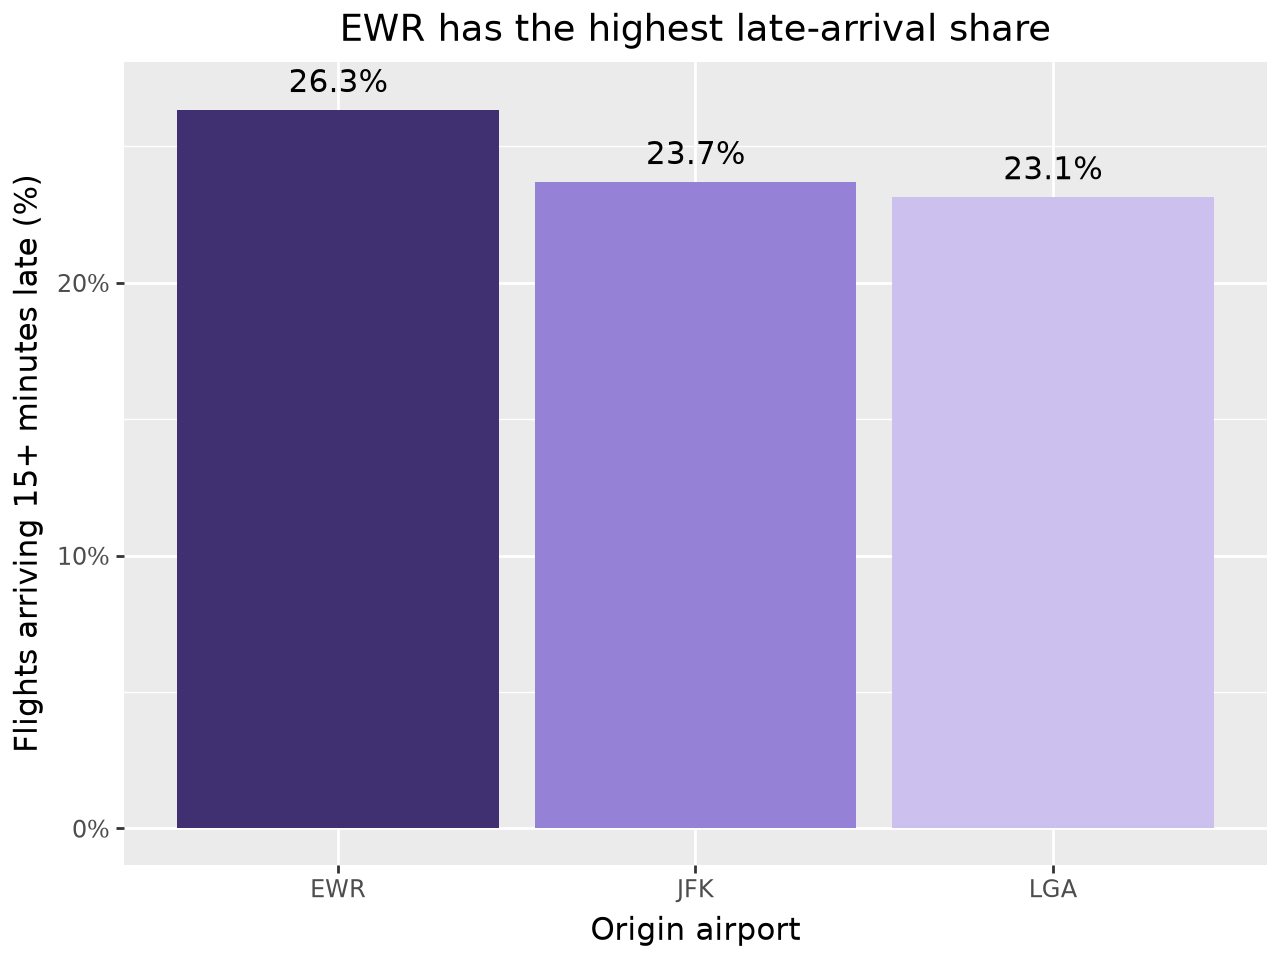

In [13]:
from plotnine import aes, geom_text

figure_final = figure_v1 + geom_text(
    aes(label="late_label"),
    va="bottom",
    nudge_y=0.4
)

figure_final

Adding percentage labels above the bars makes each airport’s exact late-arrival rate easier to read without estimating it from the axis. No data are lost, though the labels add a little visual clutter.

### (d) The caption

Among 327346 New York City flights with reported arrival delays in 2013, EWR had the highest share arriving at least 15 minutes late (26.3%), compared with 23.7% at JFK and 23.1% at LGA. EWR’s late-arrival share was 2.6 percentage points higher than JFK’s and 3.2 percentage points higher than LGA’s. The records come from the U.S. Bureau of Transportation Statistics, distributed through nycflights13. These are descriptive comparisons: airlines, routes, and departure times differ across airports, so the data do not establish that the airport itself caused the differences.

## Figure saving

In [14]:
figure_final.save("figure.png", width=8, height=5, dpi=300)

C:\Users\vikot\miniforge3\envs\research-methods\Lib\site-packages\plotnine\ggplot.py:623: PlotnineWarning: Saving 8 x 5 in image.
C:\Users\vikot\miniforge3\envs\research-methods\Lib\site-packages\plotnine\ggplot.py:624: PlotnineWarning: Filename: figure.png
